In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_11/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 11.4. NBEATSx: экзогенные признаки

До сих пор модели видели только историю самого ряда. Но цена электроэнергии зависит от нагрузки и выработки,
а системный оператор **заранее** публикует их прогнозы на завтра. Часть будущего известна в момент прогноза —
как дать это сети?

**NBEATSx** (Olivares и др., arXiv 2021, International Journal of Forecasting) — N-BEATS с экзогенными
признаками. В статье он проверялся ровно на этой задаче — прогнозе цен на рынке электроэнергии на сутки вперёд
(EPF, electricity price forecasting).

[Neural basis expansion analysis with exogenous variables: Forecasting electricity prices with NBEATSx](https://arxiv.org/abs/2104.05522)

Авторы называют у исходного N-BEATS два ограничения:
- **нет ковариат** — модель видит только окно истории самого ряда. Для EPF это критично: цену на завтра
  определяют завтрашние нагрузка и выработка, а не вчерашняя цена;
- **интерпретируемость** — хочется видеть не только прогноз, но и из чего он сложен.

NBEATSx закрывает оба пункта: признаки подаются на вход каждого блока, а в интерпретируемой версии появляется
отдельный «экзогенный» стек. Главный результат статьи (раздел 4.3.6): на пяти рынках NBEATSx точнее исходного
N-BEATS в среднем на 18.77% по всем метрикам и до 5% точнее сильных специализированных бенчмарков
(LEAR — линейная авторегрессия с Lasso, и DNN).

Разбираем:
- типы ковариат: статические, исторические, будущие известные — и как их подавать в `neuralforecast`;
- как признаки попадают внутрь блока N-BEATS;
- сколько стоит знание будущего: один и тот же признак как будущий и как исторический;
- интерпретируемый NBEATSx: прогноз = тренд + сезонность + вклад экзогенных.

In [2]:
import logging
import time
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATSx
from neuralforecast.tsdataset import TimeSeriesDataset
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=False, enable_model_summary=False, logger=False)

/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/11/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [3]:
def score(cv, by_series=False):
    """MAE и RMSE каждой модели, усреднённые по окнам кросс-валидации (и по рынкам, если by_series=False)."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, rmse], models=models)
    keys = ["metric", "unique_id"] if by_series else "metric"
    table = res.groupby(keys)[models].mean().T.round(2)
    return table.sort_values(table.columns[0])

## Данные: рынки электроэнергии Франции и Бельгии

Бенчмарк EPF: почасовые цены рынка на сутки вперёд (day-ahead, €/МВт·ч), январь 2015 — октябрь 2016.
Рядом с ценой — **прогнозы на те же часы**, опубликованные накануне:
- `gen_forecast` — прогноз выработки;
- `system_load` — прогноз нагрузки;
- `week_day` — день недели.

Отдельный файл — статические признаки рынка (one-hot индикатор).

В статье те же два рынка (EPEX-FR и EPEX-BE, Table 1) плюс Nord Pool, PJM (США) и Германия. Там на каждый
рынок 6 лет данных, тест — последние 2 года (728 суток), и модель **переобучается каждый день** перед прогнозом.
У нас тест — 5 суток, поэтому наши цифры с таблицами статьи напрямую не сравниваются.

In [4]:
URL = "https://datasets-nixtla.s3.amazonaws.com"
df = pd.read_csv(f"{URL}/EPF_FR_BE.csv", parse_dates=["ds"])
static_df = pd.read_csv(f"{URL}/EPF_FR_BE_static.csv")
print(df.shape, df.groupby("unique_id")["ds"].agg(["min", "max"]).to_dict("index"))
static_df

(32160, 6) {'BE': {'min': Timestamp('2015-01-01 00:00:00'), 'max': Timestamp('2016-10-31 23:00:00')}, 'FR': {'min': Timestamp('2015-01-01 00:00:00'), 'max': Timestamp('2016-10-31 23:00:00')}}


,unique_id,market_0,market_1
0,FR,1,0
1,BR,0,1


В статическом файле опечатка: Бельгия записана как `BR`. Без исправления статические признаки к ряду `BE`
не подтянутся — проверяйте, что ключи совпадают.

In [5]:
static_df["unique_id"] = static_df["unique_id"].replace({"BR": "BE"})
assert set(static_df["unique_id"]) == set(df["unique_id"])
df.head()

,unique_id,ds,y,gen_forecast,system_load,week_day
0,FR,2015-01-01 00:00:00,53.48,76905.0,74812.0,3
1,FR,2015-01-01 01:00:00,51.93,75492.0,71469.0,3
2,FR,2015-01-01 02:00:00,48.76,74394.0,69642.0,3
3,FR,2015-01-01 03:00:00,42.27,72639.0,66704.0,3
4,FR,2015-01-01 04:00:00,38.41,69347.0,65051.0,3


Чьи это прогнозы? Сравним признаки двух рынков в одни и те же часы:

In [6]:
wide = df.pivot(index="ds", columns="unique_id", values=["gen_forecast", "system_load"])
for col in ["gen_forecast", "system_load"]:
    print(f"{col}: совпадает у FR и BE в {(wide[col]['FR'] == wide[col]['BE']).mean():.0%} часов")
print(f"средняя нагрузка: {df['system_load'].mean() / 1000:.0f} ГВт")

gen_forecast: совпадает у FR и BE в 100% часов
system_load: совпадает у FR и BE в 100% часов
средняя нагрузка: 53 ГВт


Признаки у двух рынков **одинаковые** — это французские прогнозы (нагрузка около 53 ГВт — масштаб Франции;
у Бельгии она в разы меньше). Бельгийская цена получает их как информацию о соседнем, более крупном рынке.
Это не ошибка: в статье (раздел 4.1) прогноз французской выработки намеренно используется для обоих рынков —
со ссылкой на то, что он один из лучших предикторов бельгийских цен (рынки связаны перетоками). Но ждать, что
французские признаки объяснят бельгийскую цену так же хорошо, как французскую, не стоит.

Цены — с резкими пиками (в Бельгии до 450 €/МВт·ч при среднем около 40) и даже отрицательными значениями.

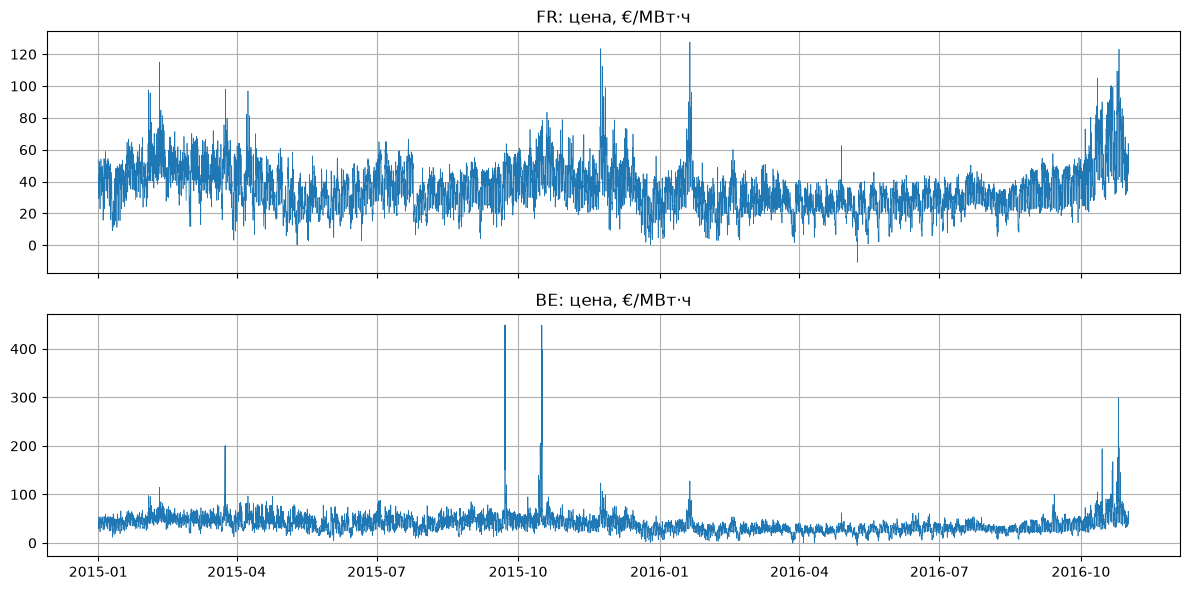

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, uid in zip(axes, ["FR", "BE"]):
    s = df[df["unique_id"] == uid]
    ax.plot(s["ds"], s["y"], lw=0.5)
    ax.set_title(f"{uid}: цена, €/МВт·ч")
fig.tight_layout()

Цена и прогноз нагрузки на одной неделе, и связь между ними на всём ряде: чем выше ожидаемая нагрузка,
тем дороже электроэнергия.

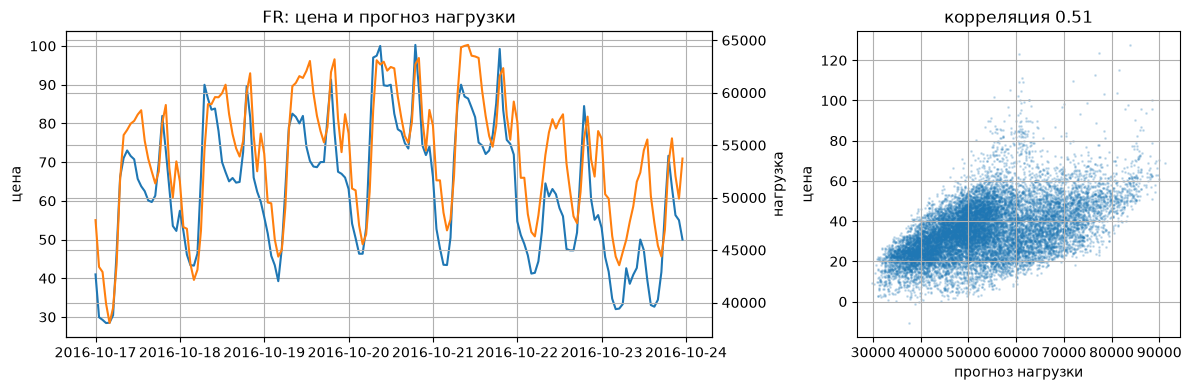

In [8]:
fr = df[df["unique_id"] == "FR"]
week = fr[fr["ds"] >= "2016-10-17"].head(7 * 24)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(week["ds"], week["y"], label="цена")
axes[0].set_ylabel("цена")
twin = axes[0].twinx()
twin.plot(week["ds"], week["system_load"], color="tab:orange", label="прогноз нагрузки")
twin.set_ylabel("нагрузка")
axes[0].set_title("FR: цена и прогноз нагрузки")
axes[1].scatter(fr["system_load"], fr["y"], s=1, alpha=0.2)
axes[1].set_xlabel("прогноз нагрузки")
axes[1].set_ylabel("цена")
axes[1].set_title(f"корреляция {fr['y'].corr(fr['system_load']):.2f}")
fig.tight_layout()

## 1. Типы ковариат

Главный вопрос к любому признаку: **будет ли известно его значение в момент прогноза?**

| тип | что это | пример | в `neuralforecast` |
|---|---|---|---|
| статические | не меняются во времени | рынок (FR / BE) | `static_df` + `stat_exog_list` |
| исторические | известны только до момента прогноза | фактическая нагрузка, цена соседнего рынка | колонки `df` + `hist_exog_list` |
| будущие известные | известны и на горизонте прогноза | календарь, прогноз оператора | колонки `df` + `futr_exog_list`, при `predict` — `futr_df` |

- Будущий признак модель видит **на всём окне: история + горизонт**. Исторический — только на истории.
- Если подать как будущий то, что на самом деле в момент прогноза неизвестно (например, фактическую нагрузку),
  на тесте метрика будет прекрасной, а в проде модели нечего будет подать. Это утечка.
- Поэтому будущие признаки должны быть **прогнозами** — и при обучении, и на тесте. В EPF `gen_forecast` и
  `system_load` — как раз прогнозы оператора, опубликованные накануне. Подавать их как будущие честно.
- Календарь известен всегда. `week_day` здесь — просто число 0…6; другие способы кодирования — sin / cos или
  эмбеддинг (`cat_exog_list`).

В статье (раздел 3.4.3) та же классификация, с двумя уточнениями:
- **статические** признаки нужны, когда одна модель обучается на много рядов: через них сеть делит знание
  между похожими рядами и при этом отличает их друг от друга (у нас — FR и BE);
- временные признаки делятся на **сезонные** (календарь, тренд, гармоники — помогают видеть сезонность длиннее
  окна истории) и **предметные** (для EPF — прогнозы нагрузки и выработки ВИЭ на сутки вперёд).

Отсюда полезное следствие: окно у модели — всего неделя, но через календарные признаки (месяц, праздники) она
может учесть сезонность длиннее окна, которой в истории не видно. В нашем наборе из календаря есть только
`week_day`.

## 2. Постановка и базовые модели

Рынок на сутки вперёд: `h=24`, история — неделя (`input_size=168`), как и в статье. Одна глобальная модель на
оба рынка. Тест — 5 последних суток. Функция потерь — MAE (по умолчанию в `NBEATSx`; в статье тоже MAE).

Нормализация `robust` (медиана и MAD окна): ценовые пики меньше влияют на масштаб. `neuralforecast` применяет
тот же скейлер и к временным признакам, причём статистики считает **только по истории** окна — горизонт в них
не попадает. В статье (приложение A.5) робастная нормализация экзогенных признаков по медиане тоже стабильно
выигрывала у нормализации по стандартному отклонению.

Планка — `SeasonalNaive(24)` (вчерашние цены) и `SeasonalNaive(168)` (неделю назад). В EPF принят чуть более
хитрый наивный прогноз «похожего дня» (сноска 2 статьи): для понедельника, субботы и воскресенья — тот же день
неделю назад, для вторника–пятницы — вчера. Он понадобится ниже для метрики rMAE.

In [9]:
H = 24
L = 7 * 24
N_WINDOWS = 5
FUTR = ["gen_forecast", "system_load", "week_day"]
STAT = ["market_0", "market_1"]
common = dict(
    h=H, input_size=L, max_steps=1000, learning_rate=1e-3, scaler_type="robust", random_seed=SEED, **TRAINER_KW
)

sf = StatsForecast(
    models=[SeasonalNaive(24, alias="SeasonalNaive(24)"), SeasonalNaive(168, alias="SeasonalNaive(168)")], freq="h"
)
cv_all = sf.cross_validation(df=df[["unique_id", "ds", "y"]], h=H, n_windows=N_WINDOWS, step_size=H)
score(cv_all)

metric,mae,rmse
SeasonalNaive(24),9.38,10.99
SeasonalNaive(168),15.88,19.54


## 3. N-BEATS без признаков и NBEATSx

### Как признаки попадают в блок

Каркас тот же, что у N-BEATS (раздел 3 статьи, Figure 1). Блок $b$ стека $s$ — полносвязная сеть (FCNN),
которая по своему входу выдаёт коэффициенты разложения, а прогноз и «бэккаст» (реконструкция истории) —
это коэффициенты, умноженные на базис:

$$
h_{s,b} = \mathrm{FCNN}_{s,b}\big(y^{back}_{s,b-1},\, X\big), \qquad
\theta^{for}_{s,b} = \mathrm{LINEAR}^{for}(h_{s,b}), \qquad
\hat y^{for}_{s,b} = V^{for}_{s,b}\, \theta^{for}_{s,b}.
$$

- **Двойные остаточные связи**: следующий блок получает историю за вычетом бэккаста,
  $y^{back}_{s,b+1} = y^{back}_{s,b} - \hat y^{back}_{s,b}$, — каждый блок объясняет то, что не объяснили
  предыдущие.
- **Итоговый прогноз** — сумма прогнозов всех блоков: $\hat y^{for} = \sum_s \sum_b \hat y^{for}_{s,b}$.

Единственное отличие NBEATSx — матрица признаков $X$ на входе **каждого** блока. В статье есть два способа её
использовать:
1. **Generic-конфигурация (NBEATSx-G)**: базис — единичная матрица, т. е. сеть выдаёт $H$ значений прогноза
   напрямую. Признаки сначала сжимает свёрточный энкодер: $\hat y^{exog}_{s,b} = C_{s,b}\,\theta^{for}_{s,b}$,
   $C_{s,b} = \mathrm{TCN}(X)$ (формула 9). В переборе (Table 2) были энкодеры TCN и WaveNet — оба на
   расширенных (dilated) свёртках, которые дёшево видят длинный контекст. Порядок «generic-стек / экзогенный
   стек» тоже подбирался.
2. **Интерпретируемая конфигурация (NBEATSx-I)**: базисом служат сами признаки — разбираем в разделе 5.

В `neuralforecast` свёрточного энкодера нет, всё проще: признаки окна **разворачиваются в вектор и
дописываются к лагам цены** на входе MLP каждого блока:

$$
\text{вход блока} = \big[\, y_{t-L+1:t},\;\; x^{hist}_{t-L+1:t},\;\; x^{futr}_{t-L+1:t+H},\;\; s \,\big].
$$

Будущие признаки берутся на $L + H$ точек, исторические — на $L$, статические — один раз. Проверим размер
входа первого слоя для трёх вариантов, которые будем обучать:

In [10]:
variants = {
    "без признаков": dict(),
    "будущие + статические": dict(futr_exog_list=FUTR, stat_exog_list=STAT),
    "gen/load как исторические": dict(
        hist_exog_list=["gen_forecast", "system_load"], futr_exog_list=["week_day"], stat_exog_list=STAT
    ),
}
sizes = {name: NBEATSx(h=H, input_size=L, **kw).blocks[0].layers[0].in_features for name, kw in variants.items()}
pd.Series(sizes, name="входов в первый слой блока")

без признаков                168
будущие + статические        746
gen/load как исторические    698
Name: входов в первый слой блока, dtype: int64

- $168$ — только лаги цены;
- $168 + 3 \cdot (168 + 24) + 2 = 746$ — три будущих признака на всём окне плюс два статических;
- $168 + 2 \cdot 168 + 1 \cdot 192 + 2 = 698$ — то же, но нагрузка и выработка без горизонта.

Разница $746 - 698 = 48$ входов — это и есть «знание будущего»: прогнозы нагрузки и выработки на 24 часа
завтрашнего дня. В разделе 4 измерим, сколько оно стоит.

Обучим N-BEATS и NBEATSx. Одна и та же архитектура (`NBEATSx` с настройками по умолчанию: стеки
`identity`, `trend`, `seasonality` по одному блоку), разница только в списках признаков.
Без списков `NBEATSx` — обычный N-BEATS.

Экзогенные признаки — это **интерфейс данных**: колонки лежат в `df`, статика — в `static_df`,
а модель получает только названия колонок.

In [11]:
models = [
    NBEATSx(alias="N-BEATS (без признаков)", **common),
    NBEATSx(alias="NBEATSx", futr_exog_list=FUTR, stat_exog_list=STAT, **common),
]
nf = NeuralForecast(models=models, freq="h")
start = time.time()
cv = nf.cross_validation(df=df, static_df=static_df, n_windows=N_WINDOWS, step_size=H)
print(f"обучение + прогноз: {time.time() - start:.0f} с")
cv_all = cv_all.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

обучение + прогноз: 91 с


metric,mae,rmse
NBEATSx,8.80,10.51
SeasonalNaive(24),9.38,10.99
N-BEATS (без признаков),11.75,14.02
SeasonalNaive(168),15.88,19.54


Без признаков нейросеть **не обходит** вчерашние цены: по одной истории цену завтра не угадать.
С прогнозами оператора ошибка заметно падает. По рынкам:

In [12]:
score(cv_all, by_series=True)

metric                     mae          rmse       
unique_id                   BE     FR     BE     FR
SeasonalNaive(24)         9.97   8.79  12.11   9.87
NBEATSx                  12.43   5.17  14.63   6.40
N-BEATS (без признаков)  13.70   9.80  16.52  11.52
SeasonalNaive(168)       19.21  12.54  24.37  14.71

Выигрыш почти целиком приходится на Францию: там ошибка падает почти вдвое. В Бельгии NBEATSx лучше N-BEATS
без признаков, но вчерашние цены не обходит. Признаки — французские, бельгийская цена слабее с ними связана
(корреляция с нагрузкой около 0.3 против 0.5 у Франции) и сильнее «скачет». Признак помогает настолько,
насколько он действительно объясняет целевую переменную.

Что в статье (Table 3, ансамбли, MAE на двух годах теста):

| рынок | N-BEATS | NBEATSx-G | NBEATSx-I | DNN | LEARx |
|---|---|---|---|---|---|
| EPEX-FR | 4.74 | 3.81 | 3.79 | 3.87 | 3.98 |
| EPEX-BE | 6.84 | 5.95 | 6.11 | 5.87 | 6.14 |

- Направление то же: признаки снижают ошибку на обоих рынках. Масштаб скромнее нашего (около 20%, а не
  вдвое) — у нас 5 суток теста, модель без подбора гиперпараметров и ансамбля, так что разброс большой.
- Бельгия и в статье трудный рынок: вместе с PJM это рынок, где ансамбль NBEATSx не обходит DNN по MAE
  (в тексте статьи разница названа незначимой: 1.1% для BE и 0.24% для PJM).
- **Признаки важнее архитектуры.** Линейная авторегрессия с признаками ARx1 обходит N-BEATS без признаков на
  трёх рынках из пяти (Table 3, MAE: NP 2.01 против 2.08, FR 4.56 против 4.74, DE 4.36 против 5.31), а LEARx —
  на всех пяти. Глубокая сеть без внешней информации проигрывает простой регрессии, которая её получает.
- На кривых обучения (Figure A.2, рынок NP, по четыре сида) прогоны с признаками и без образуют два отдельных
  «пучка»: на валидации MAE выходит на плато около 1.2 и около 1.8, и с ростом числа итераций разрыв не
  закрывается.

В EPF принято сравнивать модели относительной ошибкой **rMAE** — MAE модели, делённая на MAE наивного прогноза
«похожего дня»:

$$
\mathrm{rMAE} = \frac{\sum_{d,h} |y_{d,h} - \hat y_{d,h}|}{\sum_{d,h} |y_{d,h} - \hat y^{naive}_{d,h}|}.
$$

Значение меньше 1 — модель лучше наивного прогноза. В отличие от MAE, rMAE не зависит от уровня цен, и его
можно сравнивать между рынками и периодами. Посчитаем его по рынкам:

In [13]:
def similar_day_naive(ds):
    """Момент, цену которого берёт наивный прогноз EPF: пн, сб, вс — неделю назад, вт–пт — сутки назад."""
    lag_hours = np.where(ds.dt.dayofweek.isin([0, 5, 6]), 7 * 24, 24)
    return ds - pd.to_timedelta(lag_hours, unit="h")


prices = df.set_index(["unique_id", "ds"])["y"]
naive = prices.reindex(pd.MultiIndex.from_arrays([cv_all["unique_id"], similar_day_naive(cv_all["ds"])])).to_numpy()
model_cols = [c for c in cv_all.columns if c not in ("unique_id", "ds", "cutoff", "y")]
abs_err = cv_all[model_cols].sub(cv_all["y"], axis=0).abs()
naive_err = (cv_all["y"] - naive).abs()
rmae = abs_err.groupby(cv_all["unique_id"]).sum().div(naive_err.groupby(cv_all["unique_id"]).sum(), axis=0)
rmae.T.round(2).sort_values("FR")

unique_id,BE,FR
NBEATSx,0.89,0.56
SeasonalNaive(24),0.72,0.95
N-BEATS (без признаков),0.99,1.06
SeasonalNaive(168),1.38,1.36


- Во Франции NBEATSx почти вдвое лучше наивного прогноза, в Бельгии — лишь немного.
- В Бельгии на этих пяти сутках «вчерашние цены» оказались заметно лучше «похожего дня»: в тест попали
  суббота, воскресенье и понедельник, для которых наивный прогноз EPF берёт цены недельной давности.
  Так что rMAE зависит и от того, какие дни недели попали в короткий тест.
- Для ориентира: в статье rMAE лучших моделей — 0.64 на FR и 0.72–0.75 на BE (Table 3), на двух годах теста.
  Наши пять суток слишком короткий тест для точного сравнения, но порядок величин сопоставим.

### Прогноз с будущими признаками

В `cross_validation` будущие признаки на горизонте берутся из `df`. Для «боевого» прогноза их нужно
передать явно в `futr_df` — значения признаков на `h` шагов вперёд для каждого ряда. Без них `predict`
упадёт: модель не знает, какие будут нагрузка и выработка.

Сделаем прогноз от последнего `cutoff` и сверим с `cross_validation`:

In [14]:
cutoff_last = cv_all["cutoff"].max()
history = df[df["ds"] <= cutoff_last]
futr_df = df[df["ds"] > cutoff_last].drop(columns="y")  # прогнозы оператора на завтра, без цены
print("ожидаемые строки futr_df:", nf.make_future_dataframe(df=history).shape[0], "| передаём:", len(futr_df))

forecast = nf.predict(df=history, static_df=static_df, futr_df=futr_df)
check = forecast.merge(cv_all[cv_all["cutoff"] == cutoff_last], on=["unique_id", "ds"], suffixes=("", "_cv"))
assert np.allclose(check["NBEATSx"], check["NBEATSx_cv"], atol=1e-3)
forecast.head()

ожидаемые строки futr_df: 48 | передаём: 48


,unique_id,ds,N-BEATS (без признаков),NBEATSx
0,BE,2016-10-31 00:00:00,39.981785,38.191284
1,BE,2016-10-31 01:00:00,34.906296,29.536068
2,BE,2016-10-31 02:00:00,31.955990,24.426239
3,BE,2016-10-31 03:00:00,27.152428,16.947224
4,BE,2016-10-31 04:00:00,24.711620,18.810753


## 4. Сколько стоит знание будущего

Подадим **те же** `gen_forecast` и `system_load` как исторические: модель видит их только на неделе истории,
но не на горизонте. Календарь оставляем будущим — он известен всегда.

Разница между «будущими» и «историческими» признаками — это ценность того, что оператор публикует прогнозы
на завтра. Архитектурно это те самые 48 входов блока из раздела 3: всё остальное у двух моделей одинаково.
В статье такого эксперимента нет — там признаки всегда подаются как будущие.

In [15]:
nf_hist = NeuralForecast(
    models=[
        NBEATSx(
            alias="NBEATSx (как исторические)",
            hist_exog_list=["gen_forecast", "system_load"],
            futr_exog_list=["week_day"],
            stat_exog_list=STAT,
            **common,
        )
    ],
    freq="h",
)
cv = nf_hist.cross_validation(df=df, static_df=static_df, n_windows=N_WINDOWS, step_size=H)
cv_all = cv_all.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

metric,mae,rmse
NBEATSx,8.80,10.51
SeasonalNaive(24),9.38,10.99
NBEATSx (как исторические),10.19,12.38
N-BEATS (без признаков),11.75,14.02
SeasonalNaive(168),15.88,19.54


Исторические признаки помогают меньше: прошлая нагрузка говорит о завтрашней цене хуже, чем прогноз
нагрузки на завтра. Основной выигрыш NBEATSx — в **известном будущем**.

Оговорка: пять суток — маленький тест. На 10 окнах разрыв «будущие / исторические» в среднем меньше и держится
в основном на Франции. Проверьте сами, увеличив `N_WINDOWS`.

## 5. Интерпретируемый NBEATSx

В интерпретируемой версии каждый стек раскладывает прогноз по своему **фиксированному базису**, а сеть выдаёт
только коэффициенты (раздел 3.4.1 статьи, формулы 5–7). Время на горизонте $t = (0, 1, \dots, H-1)/H$:

$$
\hat y^{trend} = \sum_{i=0}^{N_{pol}} t^i\, \theta^{trend}_i = T\theta^{trend}, \qquad
\hat y^{seas} = \sum_i \Big[\cos\big(2\pi i \tfrac{t}{N_{hr}}\big)\theta^{seas}_i
                + \sin\big(2\pi i \tfrac{t}{N_{hr}}\big)\theta^{seas}_{i+\lfloor H/2 \rfloor}\Big] = S\theta^{seas},
$$

$$
\hat y^{exog} = \sum_{k=1}^{N_x} X_k\, \theta^{exog}_k = X\theta^{exog}.
$$

- **Тренд** — полином низкой степени, **сезонность** — ряд Фурье (как в N-BEATS).
- **Экзогенный стек** (`"exogenous"`) — новое в NBEATSx. Его базис — **сами будущие признаки** на горизонте:
  столбцы матрицы $X \in \mathbb{R}^{H \times N_x}$ — это прогнозы нагрузки, выработки и т. д. на 24 часа.
  Вклад в прогноз на час $t$ — $\sum_k \theta_k\, x_k(t)$.
- Коэффициенты $\theta$ **свои для каждого окна**: их выдаёт FCNN блока по всему входу (история цены, признаки,
  статика). Авторы называют это «локальной регрессией с меняющимися во времени коэффициентами»: связь «нагрузка →
  цена» не одна на все времена, а пересчитывается под каждые сутки.

Детали реализации в `neuralforecast`: в базис экзогенного стека добавляются и статические признаки (one-hot
рынка, постоянный по горизонту) — они работают как свой для каждого рынка сдвиг. Признаки там уже
нормализованы скейлером окна.

Прогноз = уровень (последнее наблюдение окна) + тренд + сезонность + вклад экзогенных.

### Почему коэффициенты должны быть локальными

Небольшая проверка на данных. Подгоним для каждых суток отдельную прямую «цена ~ прогноз нагрузки» по 24 часам
и сравним с одной прямой на весь ряд:

,FR,BE
"наклон, глобальный",0.61,0.50
наклон по суткам: Q25,0.78,0.81
наклон по суткам: медиана,1.06,1.12
наклон по суткам: Q75,1.36,1.50
"R², глобальный",0.26,0.08
R² по суткам: медиана,0.57,0.54


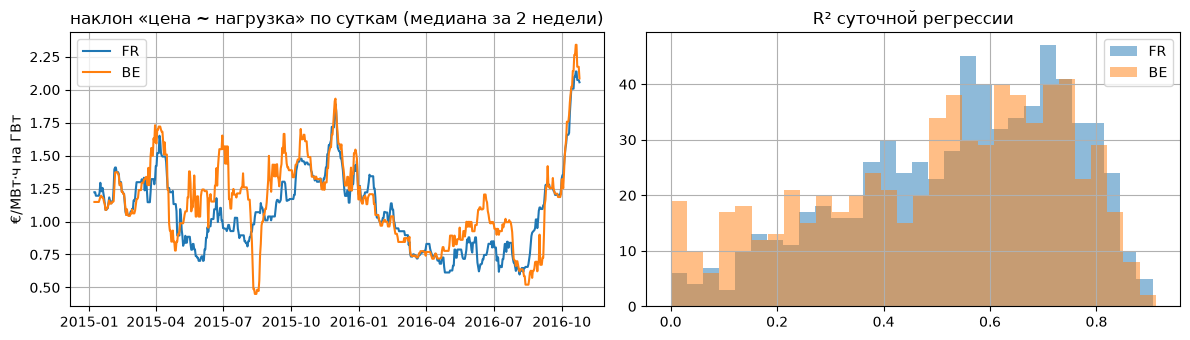

In [16]:
def daily_fit(g):
    slope, _ = np.polyfit(g["system_load"] / 1000, g["y"], 1)
    return pd.Series({"наклон": slope, "R²": g["y"].corr(g["system_load"]) ** 2})


fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
summary = {}
for uid in ["FR", "BE"]:
    s = df[df["unique_id"] == uid]
    daily = s.groupby(s["ds"].dt.normalize())[["y", "system_load"]].apply(daily_fit)
    global_slope, _ = np.polyfit(s["system_load"] / 1000, s["y"], 1)
    summary[uid] = {
        "наклон, глобальный": global_slope,
        "наклон по суткам: Q25": daily["наклон"].quantile(0.25),
        "наклон по суткам: медиана": daily["наклон"].median(),
        "наклон по суткам: Q75": daily["наклон"].quantile(0.75),
        "R², глобальный": s["y"].corr(s["system_load"]) ** 2,
        "R² по суткам: медиана": daily["R²"].median(),
    }
    axes[0].plot(daily["наклон"].rolling(14, center=True).median(), label=uid)
    axes[1].hist(daily["R²"], bins=30, alpha=0.5, label=uid)
axes[0].set_title("наклон «цена ~ нагрузка» по суткам (медиана за 2 недели)")
axes[0].set_ylabel("€/МВт·ч на ГВт")
axes[0].legend()
axes[1].set_title("R² суточной регрессии")
axes[1].legend()
fig.tight_layout()
pd.DataFrame(summary).round(2)

- Одна прямая на весь ряд объясняет мало (у Бельгии почти ничего): уровень цен «плавает» между месяцами.
- Внутри суток та же нагрузка объясняет заметную часть формы цены — медианный $R^2$ в разы выше глобального.
- Наклон меняется по сезонам: осенью и зимой каждый дополнительный ГВт нагрузки поднимает цену сильнее,
  чем летом.

Поэтому в экзогенном базисе коэффициенты выдаёт сеть под каждое окно, а не обучаются одним числом на все окна.

Пример из статьи (Figure 3): рынок NP, 18 декабря 2017 — день с необычно высокой нагрузкой. Интерпретируемый
N-BEATS без признаков сильно занижает дневные пики (остаток доходит до 18 €/МВт·ч), а у NBEATSx-I
экзогенный компонент добавляет около 15 €/МВт·ч как раз в часы пика, и остаток становится в разы меньше.
Без прогноза нагрузки модели неоткуда узнать, что завтра день необычный.

Обучим интерпретируемый NBEATSx: стеки тренда, сезонности и экзогенный.

In [17]:
interp = NBEATSx(
    alias="NBEATSx interpretable",
    stack_types=["trend", "seasonality", "exogenous"],
    futr_exog_list=FUTR,
    stat_exog_list=STAT,
    **common,
)
nf_interp = NeuralForecast(models=[interp], freq="h")
cv = nf_interp.cross_validation(df=df, static_df=static_df, n_windows=N_WINDOWS, step_size=H)
cv_all = cv_all.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

metric,mae,rmse
NBEATSx interpretable,7.46,9.12
NBEATSx,8.80,10.51
SeasonalNaive(24),9.38,10.99
NBEATSx (как исторические),10.19,12.38
N-BEATS (без признаков),11.75,14.02
SeasonalNaive(168),15.88,19.54


Интерпретируемая версия здесь не хуже, а то и лучше generic: на коротком ряде жёсткая структура базисов
работает как регуляризация. Но, как и в 11.2, на пяти сутках и одном сиде разница в пределах шума.

В статье вывод тот же: значимого компромисса между точностью и интерпретируемостью нет — NBEATSx-G и
NBEATSx-I близки на всех рынках (Table 3), и ни один бенчмарк не обошёл значимо ни одну из них (Figure 4).
Из перебора гиперпараметров (приложение A.5): чаще всего выбирался **квадратичный** тренд ($N_{pol} = 2$,
столько же стоит по умолчанию в `neuralforecast`) — квадратичного тренда и гармоник хватает, чтобы описать
суточный профиль цены.

### Разложение прогноза

Как в 11.2, `decompose` возвращает вклад каждого стека, и к каждому прибавлен центр окна — у `robust` это
**медиана** окна (torch берёт нижнюю из двух средних). Вычитаем её, чтобы вклады складывались.

Модели нужны будущие признаки, поэтому в датасет кладём историю **вместе с горизонтом**, а
`set_test_size(H)` говорит модели, что последние `H` точек — горизонт.

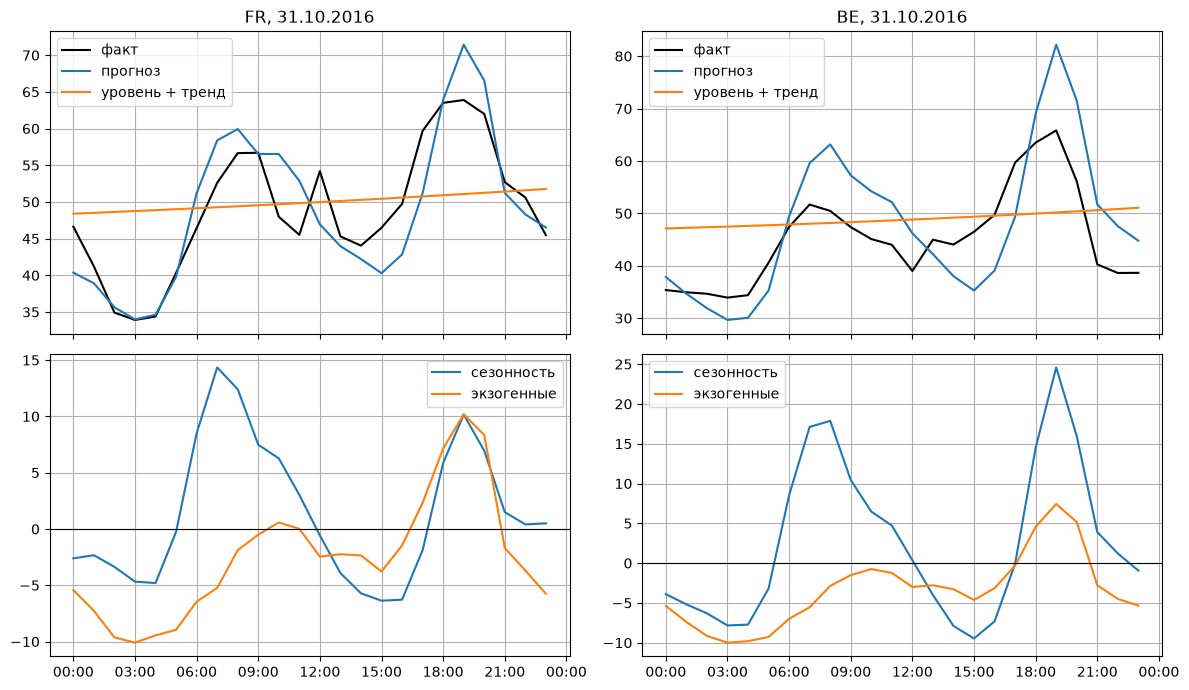

In [18]:
def forecast_components(uid, cutoff):
    model = nf_interp.models[0]
    model.set_test_size(H)
    series = df[(df["unique_id"] == uid) & (df["ds"] <= cutoff + pd.Timedelta(hours=H))]
    dataset, *_ = TimeSeriesDataset.from_df(series, static_df=static_df[static_df["unique_id"] == uid])
    blocks = model.decompose(dataset=dataset)[-1]  # (уровень + 3 стека, H)
    center = torch.tensor(series["y"].to_numpy()[-H - L : -H]).median().item()
    comp = pd.DataFrame(
        {
            "ds": series["ds"].iloc[-H:].to_numpy(),
            "уровень": blocks[0],
            "тренд": blocks[1] - center,
            "сезонность": blocks[2] - center,
            "экзогенные": blocks[3] - center,
        }
    )
    fc = cv_all[(cv_all["unique_id"] == uid) & (cv_all["cutoff"] == cutoff)]
    assert np.allclose(comp.iloc[:, 1:].sum(axis=1), fc["NBEATSx interpretable"], atol=1e-2)
    return comp.assign(y=fc["y"].to_numpy())


fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for col, uid in enumerate(["FR", "BE"]):
    comp = forecast_components(uid, cutoff_last)
    axes[0, col].plot(comp["ds"], comp["y"], color="black", label="факт")
    axes[0, col].plot(comp["ds"], comp[["уровень", "тренд", "сезонность", "экзогенные"]].sum(axis=1), label="прогноз")
    axes[0, col].plot(comp["ds"], comp["уровень"] + comp["тренд"], label="уровень + тренд")
    axes[0, col].set_title(f"{uid}, {pd.Timestamp(cutoff_last + pd.Timedelta(hours=1)):%d.%m.%Y}")
    axes[0, col].legend()
    axes[1, col].plot(comp["ds"], comp["сезонность"], label="сезонность")
    axes[1, col].plot(comp["ds"], comp["экзогенные"], label="экзогенные")
    axes[1, col].axhline(0, color="black", lw=0.8)
    axes[1, col].legend()
    axes[1, col].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout()

- **Уровень + тренд** — почти прямая: средний уровень цены на завтра.
- **Сезонность** — типичная форма суток: утренний и вечерний пики.
- **Экзогенные** — повторяет форму прогноза нагрузки: ночной провал и вечерний подъём модель объясняет
  ожидаемой нагрузкой. Во Франции, где цена сильнее связана с нагрузкой, этот вклад больше.

Та же идея, что разложение в 11.2, но теперь одна из частей прогноза — прямой вклад внешних факторов.

## 6. Для самостоятельного изучения

- **Признаки — интерфейс, а не архитектура.** Те же `futr_exog_list` / `hist_exog_list` / `stat_exog_list`
  принимают `NHITS`, `TFT`, `DeepAR` и большинство моделей `neuralforecast`. Замените `NBEATSx` на `NHITS`.
- **Утечка.** Подайте как будущий признак сдвинутую на сутки вперёд фактическую цену и посмотрите на метрику.
  Почему такой модели нельзя пользоваться?
- **Кодирование календаря.** `week_day` как категориальный (`cat_exog_list`) или sin / cos.
- **Советы из перебора гиперпараметров статьи (приложение A.5).**
  - Функции активации SELU, PReLU и Sigmoid выбирались чаще, а ReLU (по умолчанию в `neuralforecast`), Tanh и
    LeakyReLU стабильно проигрывали. Попробуйте `activation="SELU"`.
  - Batch normalization часто вредила: после двойных остаточных связей остатки близки к нулю, и нормализация
    по батчу становится численно неустойчивой.
  - Батчи 256 и 512 окон стабильно предпочитались 128 — авторы сами называют это неожиданным.
- **Ансамбль.** В статье итоговый NBEATSx — среднее четырёх моделей (разная частота нарезки окон × способ
  выбора валидации для ранней остановки); ансамбль в среднем на 3% точнее лучшей одиночной модели.
- **Вклад признаков.** `nf.explain()` (Integrated Gradients) — вклад каждого признака в каждую точку прогноза:

In [20]:
nf_explain = NeuralForecast(
    models=[NBEATSx(alias="NBEATSx", futr_exog_list=FUTR, stat_exog_list=STAT, **common)], freq="h"
)
nf_explain.fit(df=history, static_df=static_df)
fcst, explanations = nf_explain.explain(static_df=static_df, futr_df=futr_df)
expl = explanations["NBEATSx"]
futr_attr = np.abs(expl["futr_exog"]).sum(axis=(1, 2, 3, 5))  # (рядов, признаков): сумма по горизонту и времени
price_attr = np.abs(expl["insample"][..., 0]).sum(axis=(1, 2, 3, 4))  # (рядов,): история цены
importance = pd.DataFrame(futr_attr, index=fcst["unique_id"].unique(), columns=FUTR)
importance.insert(0, "история цены", price_attr)
importance.div(importance.sum(axis=1), axis=0).round(2)  # доля суммарного вклада

Using stored dataset.


,история цены,gen_forecast,system_load,week_day
BE,0.24,0.34,0.26,0.17
FR,0.19,0.35,0.28,0.18


## 7. Итоги

| вопрос | ответ |
|---|---|
| какие бывают признаки | статические, исторические, будущие известные |
| как понять, будущий ли признак | будет ли его значение известно в момент прогноза |
| как подать в `neuralforecast` | колонки `df` / `static_df` + списки `*_exog_list`; при `predict` — `futr_df` |
| как признаки входят в блок | развёрнуты в вектор и дописаны к лагам цены: будущие — на $L+H$ точек, исторические — на $L$ |
| что даёт NBEATSx | знание будущего: ошибка ниже, чем у seasonal naive и N-BEATS без признаков; в статье — около 20% к N-BEATS |
| как объяснить прогноз | экзогенный стек: базис — сами признаки, $\hat y^{exog} = X\theta$ с коэффициентами под каждое окно |
| что важнее — сеть или признаки | признаки: в статье линейная ARx1 с признаками обходит N-BEATS без них на 3 рынках из 5 |

Цены с пиками и отрицательными значениями: одного числа на каждый час мало, нужен диапазон, в котором цена
окажется с заданной вероятностью. Вероятностный прогноз — в 11.5.